AND(0, 1) = 0
AND(1, 1) = 1
AND(0, 0) = 0
AND(1, 0) = 0


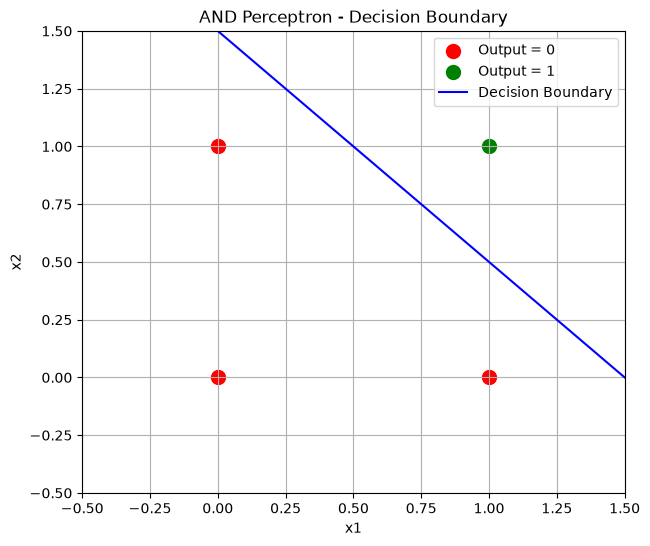


===== OTHER LOGICAL FUNCTIONS =====
Inputs: [0 0] | OR: 0 | NAND: 1
Inputs: [0 1] | OR: 1 | NAND: 1
Inputs: [1 0] | OR: 1 | NAND: 1
Inputs: [1 1] | OR: 1 | NAND: 0

===== XOR FUNCTION =====
XOR(0, 0) = 0
XOR(0, 1) = 1
XOR(1, 0) = 1
XOR(1, 1) = 0


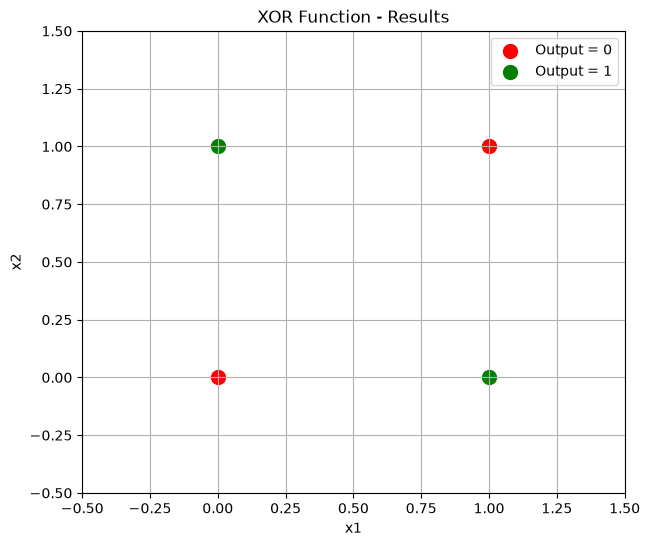

In [6]:

import numpy as np
import matplotlib.pyplot as plt

def unitStep(v):
    if v >= 0:
        return 1
    else:
        return 0

def perceptronModel(x, w, b):
    # Calcul de la somme pondérée :
    # v = w1*x1 + w2*x2 + b
    v = np.dot(w, x) + b

    # Application de la fonction d'activation
    y = unitStep(v)

    return y

def AND_logicFunction(x):
    w = np.array([1, 1])
    b = -1.5
    return perceptronModel(x, w, b)


test1 = np.array([0, 1])
test2 = np.array([1, 1])
test3 = np.array([0, 0])
test4 = np.array([1, 0])


print("AND(0, 1) =", AND_logicFunction(test1))
print("AND(1, 1) =", AND_logicFunction(test2))
print("AND(0, 0) =", AND_logicFunction(test3))
print("AND(1, 0) =", AND_logicFunction(test4))

# Résultats attendus :
# AND(0, 1) = 0
# AND(1, 1) = 1
# AND(0, 0) = 0
# AND(1, 0) = 0


# ------------------------------------------------------------
# 5. Plot Decision Boundary of AND
# ------------------------------------------------------------

# Données d'entrée
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

# Résultats du Perceptron
Y = np.array([AND_logicFunction(x) for x in X])

# Affichage des points
plt.figure(figsize=(7, 6))

# Points de classe 0
plt.scatter(
    X[Y == 0, 0],
    X[Y == 0, 1],
    color='red',
    s=100,
    label='Output = 0'
)

# Points de classe 1
plt.scatter(
    X[Y == 1, 0],
    X[Y == 1, 1],
    color='green',
    s=100,
    label='Output = 1'
)

# Decision Boundary :
# w1*x1 + w2*x2 + b = 0
# x1 + x2 - 1.5 = 0
# x2 = 1.5 - x1

x1 = np.linspace(-0.5, 1.5, 100)
x2 = 1.5 - x1

plt.plot(x1, x2, color='blue', label='Decision Boundary')

plt.xlabel('x1')
plt.ylabel('x2')
plt.title('AND Perceptron - Decision Boundary')

plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)

plt.grid(True)
plt.legend()
plt.show()


# ------------------------------------------------------------
# 6. Other Logical Functions: OR and NAND
# ------------------------------------------------------------

def OR_logicFunction(x):

    # Poids égaux à 1 et biais égal à -0.5
    w = np.array([1, 1])
    b = -0.5

    return perceptronModel(x, w, b)


def NAND_logicFunction(x):

    # Poids négatifs et biais égal à 1.5
    w = np.array([-1, -1])
    b = 1.5

    return perceptronModel(x, w, b)


print("\n===== OTHER LOGICAL FUNCTIONS =====")

for x in X:
    print(
        f"Inputs: {x} | "
        f"OR: {OR_logicFunction(x)} | "
        f"NAND: {NAND_logicFunction(x)}"
    )


# ------------------------------------------------------------
# 7. XOR Function Using a Multi-Layer Perceptron
# ------------------------------------------------------------

def XOR_logicFunction(x):

    # Hidden Layer:
    # Neuron 1 performs OR
    h1 = OR_logicFunction(x)

    # Neuron 2 performs NAND
    h2 = NAND_logicFunction(x)

    # Output Layer:
    # AND combines the outputs of the hidden layer
    hidden_outputs = np.array([h1, h2])

    w = np.array([1, 1])
    b = -1.5

    return perceptronModel(hidden_outputs, w, b)


print("\n===== XOR FUNCTION =====")

for x in X:
    print(f"XOR({x[0]}, {x[1]}) = {XOR_logicFunction(x)}")


# Résultats attendus :
# XOR(0, 0) = 0
# XOR(0, 1) = 1
# XOR(1, 0) = 1
# XOR(1, 1) = 0


# ------------------------------------------------------------
# 8. Plot XOR Results
# ------------------------------------------------------------

Y_XOR = np.array([XOR_logicFunction(x) for x in X])

plt.figure(figsize=(7, 6))

plt.scatter(
    X[Y_XOR == 0, 0],
    X[Y_XOR == 0, 1],
    color='red',
    s=100,
    label='Output = 0'
)

plt.scatter(
    X[Y_XOR == 1, 0],
    X[Y_XOR == 1, 1],
    color='green',
    s=100,
    label='Output = 1'
)

plt.xlabel('x1')
plt.ylabel('x2')
plt.title('XOR Function - Results')

plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)

plt.grid(True)
plt.legend()
plt.show()
